# **Flujo de trabajo**
# 1GEO20-ELEC
Camilo Villaroel

Angel Castillo

**1. Pasos previos**

Se buscaron repositorios del tema en cuestión, para interiorizarnos en trabajos previos.
se encontraron los siguientes github:

*   https://github.com/argenismarin/MineLab/tree/main
*   https://github.com/natannvw/Remote-Sensing-for-Mineral-Exploration-Demo/tree/main
*   https://github.com/earthrise-media/mining-detector

Se probaron los repositorios en sesiones propias del google colab para revisar su efectividad (disponibles en la carpeta del drive “pruebas repositorios”).
Se recopiló información satelital de dos bases de datos

*   *DataSet ‘ESA WorldCover 100m v200’* para obtener la imagen satelital del 2021 y la elaboración de mapas temáticos que nos permitieron explorar la zona de estudio. https://developers.google.com/earth-engine/datasets/catalog/ESA_WorldCover_v200?hl=es-419
*   *DataSet ‘Harmonized Sentinel-2 MSI: MultiSpectral Instrument, Level-2A (SR)*’ para el análisis temporal
https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED?hl=es-419



**2. Área de estudio**

Se buscó determinar un área de estudio en la zona de madre de díos en donde sean visibles las dinámicas a estudiar.

*   Sin embargo se presentaron ciertas dificultades, debido a que no se podía insertar el BBOX original debido a tener dimensiones muy extensas.
*   Se buscaron distintas alternativas, sin embargo hubieron complicaciones buscando áreas que cumplan las condiciones tanto en extensión como en interés de estudio

*   Además tuvimos leves confusiones respecto al orden de las latitudes y longitudes.

Se optó por un área de 2 kilómetros cuadrados que mezcla zona urbana, con bosque prístino, cultivos y suelo desnudo producto de la minería.
BBOX= [-69.95, -12.908, -69.93, -12.895]

Este BBOX se denominó “region”.


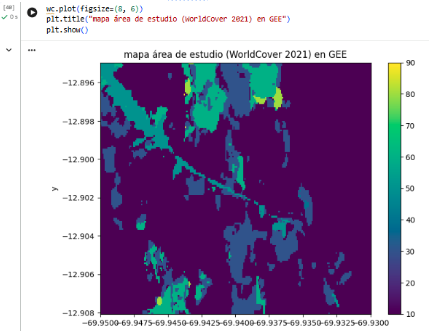

**3. Descargar imagen recortada de GEE como GeoTIFF**

Se buscó descargar una imagen satelital desde Google Earth Engine para luego descargarla como GeoTIFF; delimitada por el BBOX "region".

Luego, la imagen de cobertura del suelo ESA WorldCover, selecciona la banda "Map" y la descarga con una resolución de 10 metros

**4. Definición del cmap**
Lo siguiente realizado fue determinar la paleta de colores con la que se va a trabajar para visualizar de mejor manera los diferentes elementos del área de estudio.


*   Para esto se buscó en https://matplotlib.org/stable/users/explain/colors/colormaps.html
*   Se optó por “Accent” debido a que de tipo categorías son discretas (sin una gradiente o desvanecimiento) y tiene colores diferenciables cosa que se adapta a nuestro tipo de elementos



**5. Definición de categorías**

A partir de lo que se puede observar en una imagen satelital en “True Color” se determinaron las categorías tentativas:

*   Bosque amazónico		⇒ 10
*   Zona talada			⇒ 30
*   Cultivos			⇒ 40
*  Urbano 			⇒ 50
*   Minería (suelo desnudo) 	⇒ 60
*   Agua				⇒ 80
*   Indeterminado 		⇒ 90

A cada categoría se le asignó un valor dentro de la paleta de colores “Accent”, proveniente de la fuente Matplotlib para su identificación dentro del área de estudio.

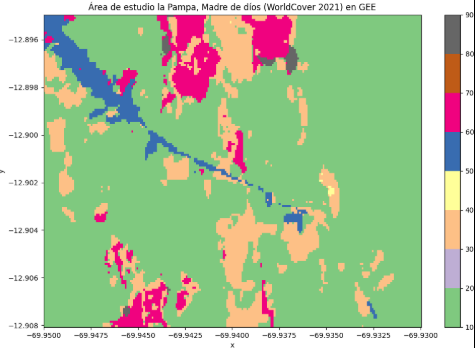

*La categoría “minería (suelo desnudo)” es provisional, ya que aún queda pendiente el tratamiento de los datos para una clasificación más específica.*


**5.Identificación porcentual de cobertura según clase**

Se agregó un código para identificar los porcentajes de cada categoría seleccionada en relación al área de estudio, obteniendo como resultado:

*   Bosque amazónico		⇒ 10
*   Zona talada			⇒ 30
*   Cultivos			⇒ 40
*  Urbano 			⇒ 50
*   Minería (suelo desnudo) 	⇒ 60
*   Agua				⇒ 80
*   Indeterminado 		⇒ 90

##Gráfico % cobertura
Se realizó un gráfico de barras de la cobertura por categoría a partir del resultado obtenido.
fue realizado a partir de matplotlib

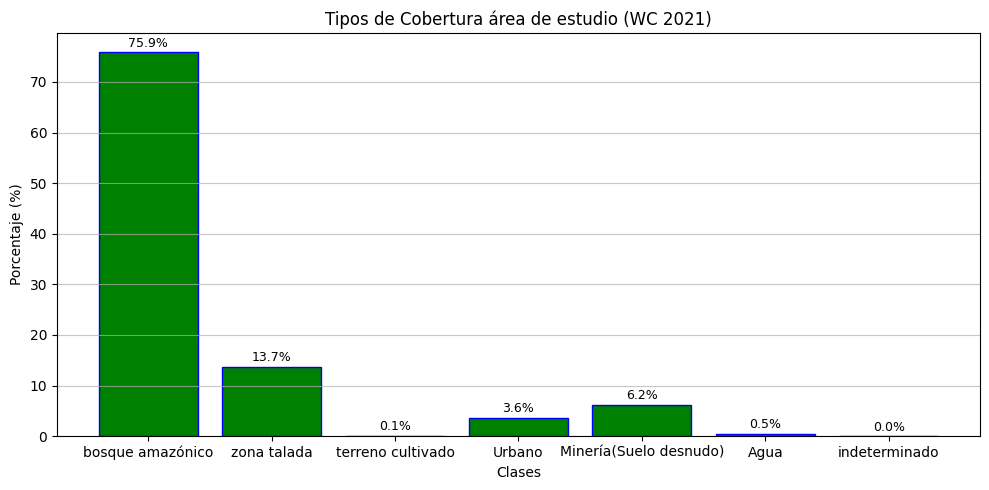

**6.Filtros para las imágenes satelitales**

A partir del DataSet de *‘Harmonized Sentinel-2 MSI: MultiSpectral Instrument, Level-2A (SR)’* se solicitó mediante un código que se escogiera escenas con una nubosidad menor a 20% en el periodo de 01/09/2026 al 01/10/2026, dentro del área de estudio del BBOX denominada “region”.

Esto dio como resultado 6 escenas, de las cuales escogió a la que tenía menor cantidad de nubosidad (0.64%) en la fecha del 17/09/2026.
 * ee.ImageCollection(“Copernicus/S2:SR_HARMONIZED”)
 * La imagen seleccionada fue: 20260917T144729_20260917T144728_T19LCF



**7. Exploración mediante NDVI**

A manera de explorar la información de la imagen seleccionada, se le aplicó un Índice de Vegetación de Diferencia Normalizada.
Se tomó la imagen normalizada, se renombró como NDVI y se realizó una operación: B8-B4. Luego, el resultado llamado NDVI toma la imagen, la transforma en un Geotiff con una resolución de 10 píxeles.
 * Para mostrar la imagen, se usó la paleta de colores ‘RdYlGn’, ya que esta gradiente permite contrastar notoriamente las zonas sin vegetación / vegetación dañada en color rojo y amarillo, y las que sí tienen vegetación saludable de verde.
 * Se definió como valor mínimo: -0.2; y como valor máximo 1 para el rango de la paleta, con la finalidad de identificar las zonas intervenidas.

 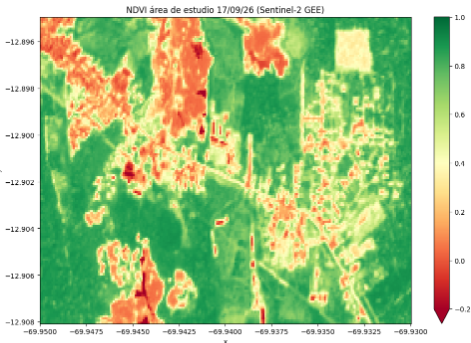

**8. Comparación temporal**

Posteriormente, para hacer una comparación temporal, bajo los mismos criterios y usando el mismo DataSet, se obtuvo una escena del 08/09/2021 con una nubosidad de 2.6% dentro la misma región.
}
 * Periodo solicitado 01/09/2021 a 01/10/2021
 * La imagen fue: 20210908T144731_20210908T145544_T19LCF




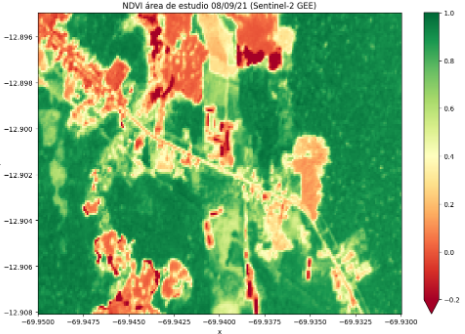

# Justificación
Mediante el análisis exploratorio de las imágenes satelitales en el área de estudio se visualiza un incremento en la deforestación. Esta se cree puede deberse en gran medida a la actividad minera en la zona, ya que a lo largo de este tramo de la Carretera Interoceánica esta actividad es muy recurrente.